# 01. Eksploracyjna analiza danych (EDA) - Secondary Mushroom Dataset

**Źródło:** UCI Machine Learning Repository, zbiór nr 848, licencja CC BY 4.0.

Cel: poznać strukturę i jakość danych, wstępnie sprawdzić tezy H1-H3 i przygotować wykresy do sprawozdania (`reports/figures`).
Notatnik działa lokalnie i w Google Colab (bez pliku lokalnego dane pobiera `ucimlrepo`).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
COLORS = {"p": "#b03a2e", "e": "#2f6b4f"}

def save(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Wczytanie danych i typy cech

In [2]:
if (RAW / "secondary_data.csv").exists():
    df = pd.read_csv(RAW / "secondary_data.csv", sep=";")
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=848)
    df = pd.concat([ds.data.targets, ds.data.features], axis=1)
df.columns = [c.replace("-", "_") for c in df.columns]
num_cols = ["cap_diameter", "stem_height", "stem_width"]
cat_cols = [c for c in df.columns if c not in num_cols + ["class"]]
print(df.shape)
pd.DataFrame({
    "typ": ["metryczna" if c in num_cols else "nominalna" for c in df.columns.drop("class")],
    "unikalne": [df[c].nunique() for c in df.columns.drop("class")],
    "braki_%": [round(df[c].isna().mean() * 100, 1) for c in df.columns.drop("class")],
}, index=df.columns.drop("class"))

(61069, 21)


,typ,unikalne,braki_%
cap_diameter,metryczna,2571,0.0
cap_shape,nominalna,7,0.0
cap_surface,nominalna,11,23.1
cap_color,nominalna,12,0.0
does_bruise_or_bleed,nominalna,2,0.0
gill_attachment,nominalna,7,16.2
gill_spacing,nominalna,3,41.0
gill_color,nominalna,12,0.0
stem_height,metryczna,2226,0.0
stem_width,metryczna,4630,0.0


In [3]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cap_diameter,61069.0,6.73,5.26,0.38,3.48,5.86,8.54,62.34
stem_height,61069.0,6.58,3.37,0.00,4.64,5.95,7.74,33.92
stem_width,61069.0,12.15,10.04,0.00,5.21,10.19,16.57,103.91


## 2. Rozkład klasy

Klasa `p` łączy grzyby trujące i o nieznanej jadalności. Klasy są w miarę zbalansowane. Przy grzybach najbardziej liczy się jednak czułość dla klasy trującej, czyli jaki procent trujących model wyłapuje.

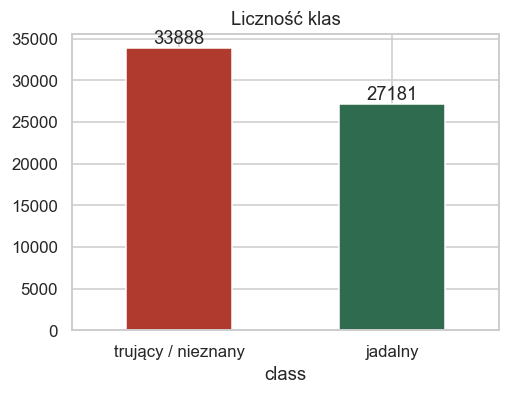

In [4]:
ax = df["class"].map({"p": "trujący / nieznany", "e": "jadalny"}).value_counts().plot.bar(color=["#b03a2e", "#2f6b4f"], rot=0, figsize=(5, 3.5))
ax.bar_label(ax.containers[0])
ax.set_title("Liczność klas")
save("01_class_balance")
plt.show()

## 3. Braki danych (teza H3)

Sprawdzamy testem χ² niezależności, czy fakt braku wartości jest powiązany z klasą.

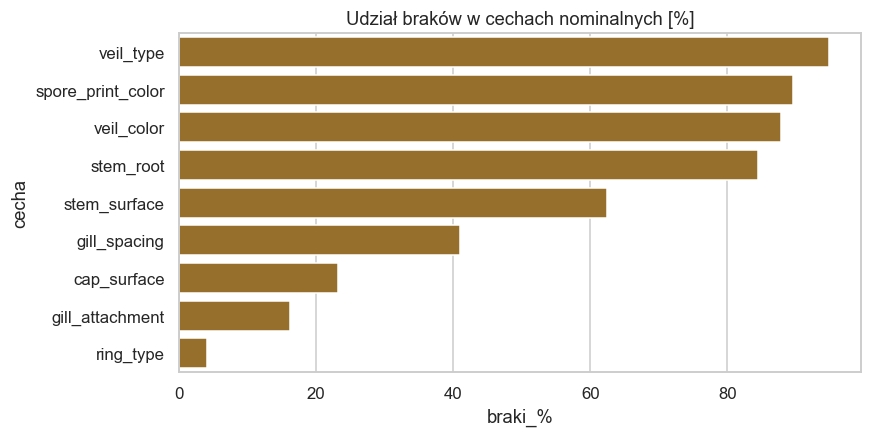

,cecha,braki_%,trujące_gdy_brak,trujące_gdy_jest,chi2,p_value
5,veil_type,94.8,0.549,0.667,169.0,1.233000e-38
8,spore_print_color,89.6,0.535,0.722,803.0,1.195159e-176
6,veil_color,87.9,0.553,0.571,9.2,2.365873e-03
3,stem_root,84.4,0.541,0.630,254.9,2.210805e-57
4,stem_surface,62.4,0.509,0.631,855.8,3.994959e-188
2,gill_spacing,41.0,0.563,0.549,12.3,4.577019e-04
0,cap_surface,23.1,0.525,0.564,66.4,3.712270e-16
1,gill_attachment,16.2,0.643,0.538,368.9,3.327604e-82
7,ring_type,4.0,0.429,0.560,165.9,5.820543e-38


In [5]:
rows = []
for c in [c for c in cat_cols if df[c].isna().any()]:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[c].isna(), df["class"]))
    rows.append({"cecha": c, "braki_%": round(df[c].isna().mean() * 100, 1),
                 "trujące_gdy_brak": round((df.loc[df[c].isna(), "class"] == "p").mean(), 3),
                 "trujące_gdy_jest": round((df.loc[df[c].notna(), "class"] == "p").mean(), 3),
                 "chi2": round(chi2, 1), "p_value": p})
miss = pd.DataFrame(rows).sort_values("braki_%", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=miss, y="cecha", x="braki_%", color="#a8741a", ax=ax)
ax.set_title("Udział braków w cechach nominalnych [%]")
save("02_missing_share")
plt.show()
miss

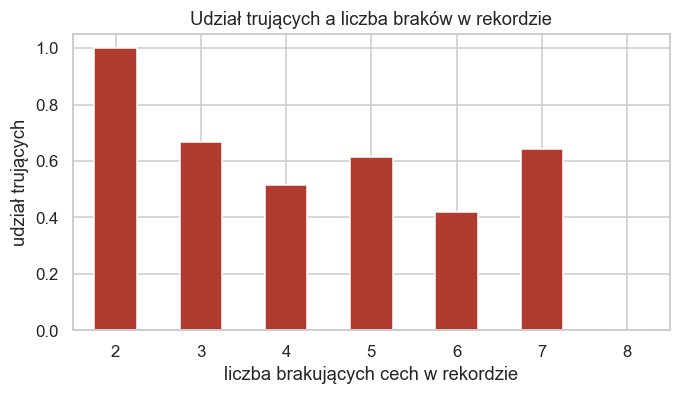

In [6]:
n_missing = df[cat_cols].isna().sum(axis=1)
ax = pd.crosstab(n_missing, df["class"], normalize="index")["p"].plot.bar(color="#b03a2e", figsize=(7, 3.5), rot=0)
ax.set_xlabel("liczba brakujących cech w rekordzie"); ax.set_ylabel("udział trujących")
ax.set_title("Udział trujących a liczba braków w rekordzie")
save("03_missing_count")
plt.show()

**Wniosek (H3):** braki zależą od klasy (dla 7 z 9 cech p < 1e-15), więc nie są losowe. W ETL zastępujemy brak osobną kategorią `missing` zamiast usuwać rekordy lub imputować.

## 4. Cechy metryczne

Rozkłady są prawoskośne, więc zamiast testu t używamy nieparametrycznego testu U Manna-Whitneya.

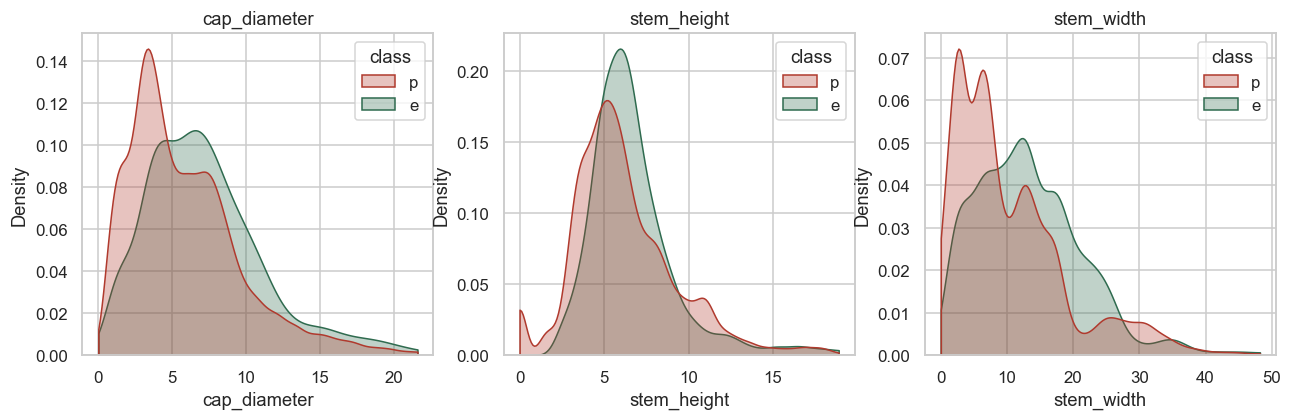

,cecha,mediana_trujące,mediana_jadalne,p_value,efekt_rb
0,cap_diameter,4.98,6.71,0.000000e+00,0.234
1,stem_height,5.63,6.24,3.872320e-235,0.154
2,stem_width,7.66,12.59,0.000000e+00,0.271


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=df, x=c, hue="class", common_norm=False, fill=True, alpha=0.3, ax=ax,
                palette=COLORS, clip=(0, df[c].quantile(0.99)))
    ax.set_title(c)
save("04_numeric_kde")
plt.show()

rows = []
for c in num_cols:
    a, b = df.loc[df["class"] == "p", c], df.loc[df["class"] == "e", c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"cecha": c, "mediana_trujące": a.median(), "mediana_jadalne": b.median(),
                 "p_value": p, "efekt_rb": round(1 - 2 * u / (len(a) * len(b)), 3)})
pd.DataFrame(rows)

**Wniosek:** trujące grzyby są przeciętnie mniejsze, różnice są istotne, ale efekt jest mały i rozkłady mocno się pokrywają. Same wymiary nie wystarczą.

## 5. Cechy nominalne i "reguły ludowe" (teza H2)

Czy istnieje jedna wartość cechy, która z dużym wsparciem potwierdza jadalność?

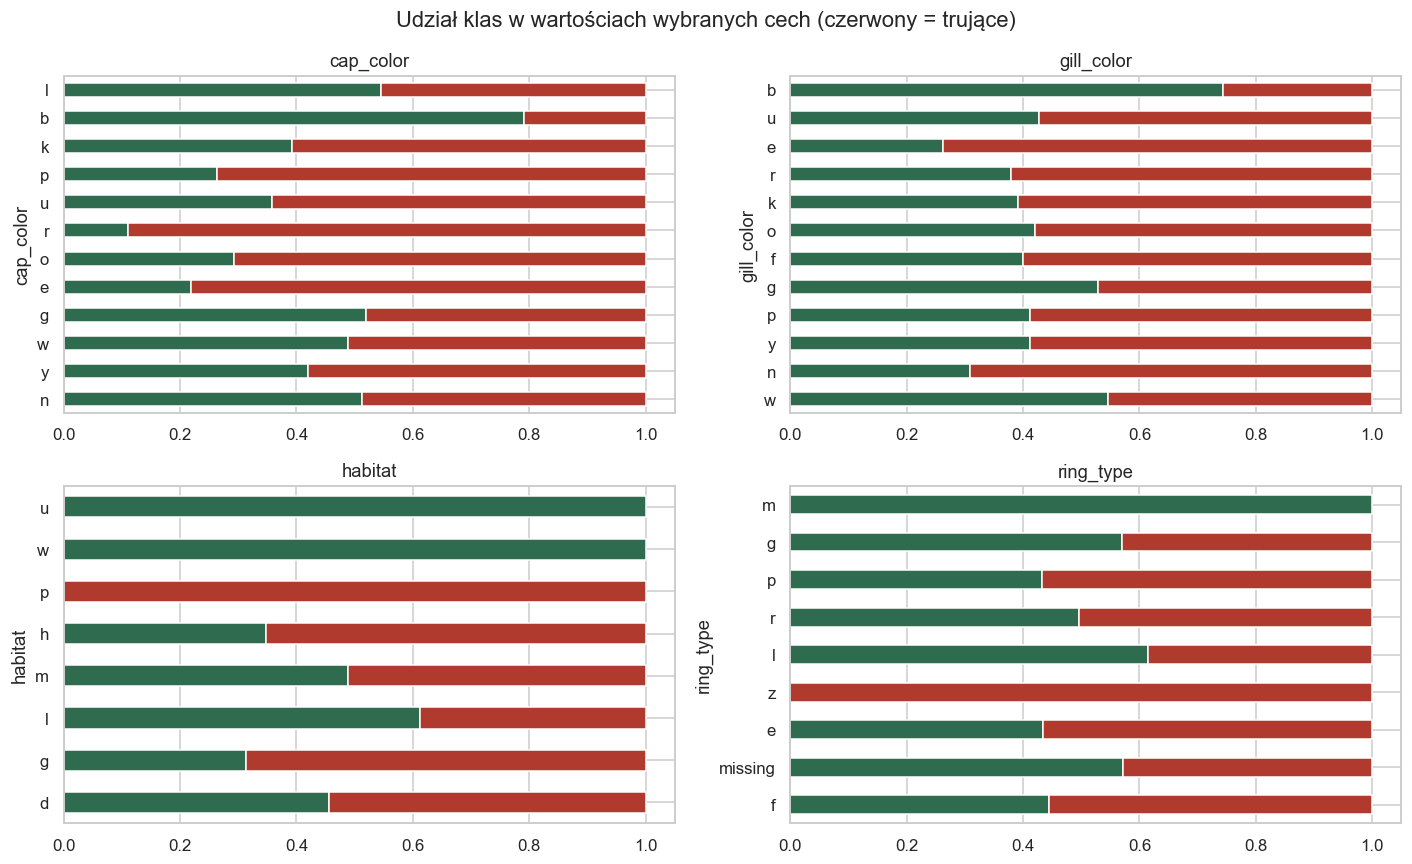

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.flat, ["cap_color", "gill_color", "habitat", "ring_type"]):
    t = pd.crosstab(df[c].fillna("missing"), df["class"])
    t = t.loc[t.sum(axis=1).sort_values(ascending=False).index]
    t.div(t.sum(axis=1), axis=0).plot.barh(stacked=True, ax=ax, color=COLORS, legend=False)
    ax.set_title(c)
fig.suptitle("Udział klas w wartościach wybranych cech (czerwony = trujące)")
plt.tight_layout()
save("05_category_profiles")
plt.show()

In [9]:
rules = []
for c in cat_cols:
    g = df.groupby(c)["class"].agg(n="size", edible=lambda s: (s == "e").mean())
    for v, r in g.iterrows():
        if r.n / len(df) >= 0.01:
            rules.append({"reguła": f"{c} = {v}", "wsparcie": round(r.n / len(df), 3), "udział_jadalnych": round(r.edible, 3)})
pd.DataFrame(rules).sort_values("udział_jadalnych", ascending=False).head(10)

,reguła,wsparcie,udział_jadalnych
18,cap_color = b,0.020,0.792
42,gill_color = b,0.016,0.744
36,gill_attachment = p,0.098,0.706
54,stem_root = b,0.052,0.667
34,gill_attachment = e,0.092,0.625
83,ring_type = l,0.023,0.615
94,habitat = l,0.052,0.612
68,stem_color = g,0.043,0.607
99,season = w,0.086,0.607
4,cap_shape = p,0.043,0.603


**Wniosek (H2):** żadna wartość o wsparciu ≥ 1% nie daje nawet 80% jadalnych (najlepsza `cap_color = b`, 79%). Istnieją natomiast wartości, które zawsze oznaczają grzyb trujący (np. `ring_type = z`).

## 6. Struktura gatunkowa (teza H1)

Według opisu zbioru dane wygenerowano z 173 gatunków, po 353 rekordy na gatunek. Sprawdzamy, czy plik jest ułożony blokami po 353 wiersze (jeden blok = jeden gatunek).

In [10]:
df["species_id"] = df.index // 353
print("rekordów na gatunek:", df.groupby("species_id").size().unique())
print("liczba bloków:", df["species_id"].nunique())
print("klasa stała w każdym bloku:", (df.groupby("species_id")["class"].nunique() == 1).all())

rekordów na gatunek: [353]
liczba bloków: 173
klasa stała w każdym bloku: True


In [11]:
within = df.groupby("species_id")[num_cols].std().mean()
between = df.groupby("species_id")[num_cols].mean().std()
pd.DataFrame({"odchylenie wewnątrz gatunku": within, "odchylenie między gatunkami": between}).round(2)

,odchylenie wewnątrz gatunku,odchylenie między gatunkami
cap_diameter,0.92,5.16
stem_height,0.76,3.26
stem_width,1.24,9.87


**Wniosek:** każdy blok ma jedną klasę, a rekordy w bloku są do siebie dużo bardziej podobne niż rekordy z różnych bloków, więc bloki to gatunki. Losowy podział wierszy umieści ten sam gatunek w treningu i w teście, więc zawyży wyniki. Dlatego w `train.py` oceniamy modele także na gatunkach wstrzymanych z treningu.

## 7. Podsumowanie

| Teza | Wstępny wynik EDA |
|---|---|
| H1: wysoka trafność dotyczy tylko gatunków znanych | dane mają silną strukturę gatunkową, losowy podział zawyży wyniki (weryfikacja w `train.py`) |
| H2: brak prostej reguły jadalności | żadna pojedyncza wartość nie potwierdza jadalności, wymiary się nakładają |
| H3: braki danych są informacyjne | braki silnie zależą od klasy |